# Prediction model for "Bank Marketing" Database
Dataset contains information about phone calls marketing campaigns of Prortugese banks who want to open bank accounts for clients. We want to classificate if call will tends to deposit mony in bank account.
[link to dataset](https://archive.ics.uci.edu/dataset/222/bank+marketing)


<div><div class="overflow-x-auto"><table class="table my-4 w-full"><thead><tr><th>Variable Name</th><th>Role</th><th>Type</th><th>Demographic</th><th>Description</th><th>Units</th><th>Missing Values</th></tr></thead> <tbody><tr><td>age</td><td>Feature</td><td>Integer</td><td>Age</td><td></td><td></td><td>no</td> </tr><tr><td>job</td><td>Feature</td><td>Categorical</td><td>Occupation</td><td>type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')</td><td></td><td>no</td> </tr><tr><td>marital</td><td>Feature</td><td>Categorical</td><td>Marital Status</td><td>marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)</td><td></td><td>no</td> </tr><tr><td>education</td><td>Feature</td><td>Categorical</td><td>Education Level</td><td>(categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')</td><td></td><td>no</td> </tr><tr><td>default</td><td>Feature</td><td>Binary</td><td></td><td>has credit in default?</td><td></td><td>no</td> </tr><tr><td>balance</td><td>Feature</td><td>Integer</td><td></td><td>average yearly balance</td><td>euros</td><td>no</td> </tr><tr><td>housing</td><td>Feature</td><td>Binary</td><td></td><td>has housing loan?</td><td></td><td>no</td> </tr><tr><td>loan</td><td>Feature</td><td>Binary</td><td></td><td>has personal loan?</td><td></td><td>no</td> </tr><tr><td>contact</td><td>Feature</td><td>Categorical</td><td></td><td>contact communication type (categorical: 'cellular','telephone') </td><td></td><td>yes</td> </tr><tr><td>day_of_week</td><td>Feature</td><td>Date</td><td></td><td>last contact day of the week</td><td></td><td>no</td> </tr><tr><td>month</td><td>Feature</td><td>Date</td><td></td><td>last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')</td><td></td><td>no</td> </tr><tr><td>duration</td><td>Feature</td><td>Integer</td><td></td><td> last contact duration, in seconds (numeric). Important note:  this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.</td><td></td><td>no</td> </tr><tr><td>campaign</td><td>Feature</td><td>Integer</td><td></td><td>number of contacts performed during this campaign and for this client (numeric, includes last contact)</td><td></td><td>no</td> </tr><tr><td>pdays</td><td>Feature</td><td>Integer</td><td></td><td>number of days that passed by after the client was last contacted from a previous campaign (numeric; -1 means client was not previously contacted)</td><td></td><td>yes</td> </tr><tr><td>previous</td><td>Feature</td><td>Integer</td><td></td><td>number of contacts performed before this campaign and for this client</td><td></td><td>no</td> </tr><tr><td>poutcome</td><td>Feature</td><td>Categorical</td><td></td><td>outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')</td><td></td><td>yes</td> </tr><tr><td>y</td><td>Target</td><td>Binary</td><td></td><td>has the client subscribed a term deposit?</td><td></td><td>no</td> </tr></tbody></table></div> <div class="my-4 flex flex-wrap items-center justify-end gap-4"><label><span data-svelte-h="svelte-b2pcbx">Rows per page</span> <select class="select select-primary select-sm rounded-full"><option value="5">5</option><option value="10">10</option><option value="15">15</option><option value="20">20</option><option value="25">25</option></select></label> <p><span>0 to</span> <span>17 of</span> <span>17</span></p> <div class="btn-group"><button class="btn btn-primary btn-sm" aria-label="Previous Page" disabled=""><svg viewBox="0 0 24 24" width="20" height="20"><path fill="currentColor" d="m14 18l-6-6l6-6l1.4 1.4l-4.6 4.6l4.6 4.6z"></path></svg></button> <button class="btn btn-primary btn-sm" aria-label="Next Page" disabled=""><svg viewBox="0 0 24 24" width="20" height="20"><path fill="currentColor" d="M12.6 12L8 7.4L9.4 6l6 6l-6 6L8 16.6z"></path></svg></button></div></div></div>

In [21]:
#import libraries
library(tidyverse)
if (!requireNamespace("patchwork", quietly = TRUE)) {
  install.packages("patchwork")
}
library(patchwork)

Instalowanie pakietu w ‘/home/ciastek/R/x86_64-pc-linux-gnu-library/4.5’
(ponieważ ‘lib’ nie jest określony)



In [46]:
#import data
bank_marketing <- read_csv2(file = "./bank/bank-full.csv", col_names = TRUE) |> as_data_frame()


ℹ Using "','" as decimal and "'.'" as grouping mark. Use `read_delim()` for more control.

Rows: 45211 Columns: 17
── Column specification ────────────────────────────────────────────────────────
Delimiter: ";"
chr (10): job, marital, education, default, housing, loan, contact, month, p...
dbl  (7): age, balance, day, duration, campaign, pdays, previous

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [48]:
print(bank_marketing)

# A tibble: 45,211 × 17
     age job       marital education default balance housing loan  contact   day
   <dbl> <chr>     <chr>   <chr>     <chr>     <dbl> <chr>   <chr> <chr>   <dbl>
 1    58 manageme… married tertiary  no         2143 yes     no    unknown     5
 2    44 technici… single  secondary no           29 yes     no    unknown     5
 3    33 entrepre… married secondary no            2 yes     yes   unknown     5
 4    47 blue-col… married unknown   no         1506 yes     no    unknown     5
 5    33 unknown   single  unknown   no            1 no      no    unknown     5
 6    35 manageme… married tertiary  no          231 yes     no    unknown     5
 7    28 manageme… single  tertiary  no          447 yes     yes   unknown     5
 8    42 entrepre… divorc… tertiary  yes           2 yes     no    unknown     5
 9    58 retired   married primary   no          121 yes     no    unknown     5
10    43 technici… single  secondary no          593 yes     no    unknown     5
# ℹ 

In [49]:
bank_marketing$balance

[1]   2143     29      2   1506      1    231    447      2    121    593
   [11]    270    390      6     71    162    229     13     52     60      0
   [21]    723    779     23     50      0   -372    255    113   -246    265
   [31]    839    378     39      0  10635     63     -7     -3    506      0
   [41]   2586     49    104    529     96   -171   -364      0      0      0
   [51]   1291   -244      0    -76   -103    243    424    306     24    179
   [61]      0    989    249    790    154   6530    100     59   1205  12223
   [71]   5935     25    282     23   1937    384    582     91      0      1
   [81]    206    164    690   2343    137    173     45   1270     16    486
   [91]     50    152    290     54    -37    101    383     81      0    229
  [101]   -674     90    128    179      0     54    151     61     30    523
  [111]     31     79    -34    448     81    144    351    -67    262      0
  [121]     56     26      3     41      7    105    818    -16      0   2476
  [131]   1185    217   1685    802      0     94      0      0    517    265
  [141]    947      3     42     37     57     22      8    293      3    348
  [151]    -19      0     -4     18    139      0   1883    216    782    904
  [161]   1705     47    176   1225     86     82    271   1378    184      0
  [171]      0   1357     19    434     92   1151     41     51    214   1161
  [181]     37    787     59    253    211    235   4384   4080     53      0
  [191]   2127    377     73    445    243    307    155    173    400   1428
  [201]    219      7    575    298      0   5699    176    517    257     56
  [211]   -390    330    195    301    -41    483     28     13    965    378
  [221]    219    324    -69      0    205    278   1065     34   1033   1467
  [231]    -12    388    294   1827    627     25    315      0     66     -9
  [241]    349    100      0    434   3237    275      0    207    483   2248
  [251]    428      0      0    140    297    279    901   2573    143    475
  [261]     70    318    275    742    236     25    600   -349    183      0
  [271]      0      0   1078    155    190    319   -185     47    570     19
  [281]     61    -62    258     76      0    352    368    339   1331    672
  [291]     58    447    423      0     19     13      3     82     28    792
  [301]    408    531    211     62    257   1234    313     89    129      0
  [311]    353    851     96    398    193   -358    539      0      0    490
  [321]      0    403    161   2558     98    115    436    831    206    290
  [331]      1     57   -457   1387  24598     30   1022     56     -2    121
  [341]    842    693   -333   1533     46     18     44   -100    510    685
  [351]    187     66    560      0     27     12     34   1068    211    377
  [361]    263   1263      8    126    230    841    308      1     86    157
  [371]     22     46   1293    122    131    143    393     98      0    224
  [381]    757    245   8486    350     20   1667    345     10    830     29
  [391]    545   8730    477      4   1205      0    263      1    283    206
  [401]     17    141     16    206      7      0      0   1927    284   1660
  [411]    406    230    -25    182   1169     67     77      0     55     72
  [421]    163    151    113      0      9    375   1142   2102   4325    217
  [431]    131   1680      0     46    320    183     39    560    469    530
  [441]     61    242    139      0    367    228  45248    -84    310    132
  [451]    797     71      2    231    270    274   -109      1    -60     89
  [461]    -11      0   -509    408     58   1640     20     71     52    292
  [471]    424    109   1044    983    869    668    964    301    140   1877
  [481]   1127    871    767      0    209      0    110    -76    178    -66
  [491]      0      1      0   5345   -209      0     42     41    -99     17
  [501]    276   -170    230      9    946   1297   -331     44     15    712
  [511]   5435    507    3

In [78]:
p1 <- ggplot(bank_marketing, aes(x = age, fill = y)) +
  geom_histogram(binwidth = 4, color = "white") +
  scale_fill_manual(values = c("yes" = "darkgreen", "no" = "tomato")) +
  labs(x = "Age", y = "Count", fill = "Has subscribed",
       title = "Distribution of age by subscription") +
  theme_minimal()

p2 <- ggplot(bank_marketing, aes(x = education, fill = y)) +
  geom_bar(color = "white") +
  scale_fill_manual(values = c("yes" = "darkgreen", "no" = "tomato")) +
  labs(x = "Education", y = "Count", fill = "Has subscribed",
       title = "Education level by subscription") +
  theme_minimal()

p3 <- ggplot(bank_marketing, aes(x = job, fill = y)) +
  geom_bar(color = "white") +
  scale_fill_manual(values = c("yes" = "darkgreen", "no" = "tomato")) +
  labs(x = "Job", y = "Count", fill = "Has subscribed",
       title = "Job type by subscription") +
  theme_minimal()

p4 <- ggplot(filter(bank_marketing, between(balance, -300, 5000)),
             aes(x = balance, fill = y)) +
  geom_histogram(binwidth = 100, color = "white") +
  scale_fill_manual(values = c("yes" = "darkgreen", "no" = "tomato")) +
  labs(x = "Account balance (-300 to 5000)", y = "Count", fill = "Has subscribed",
       title = "Account balance by subscription") +
  theme_minimal()

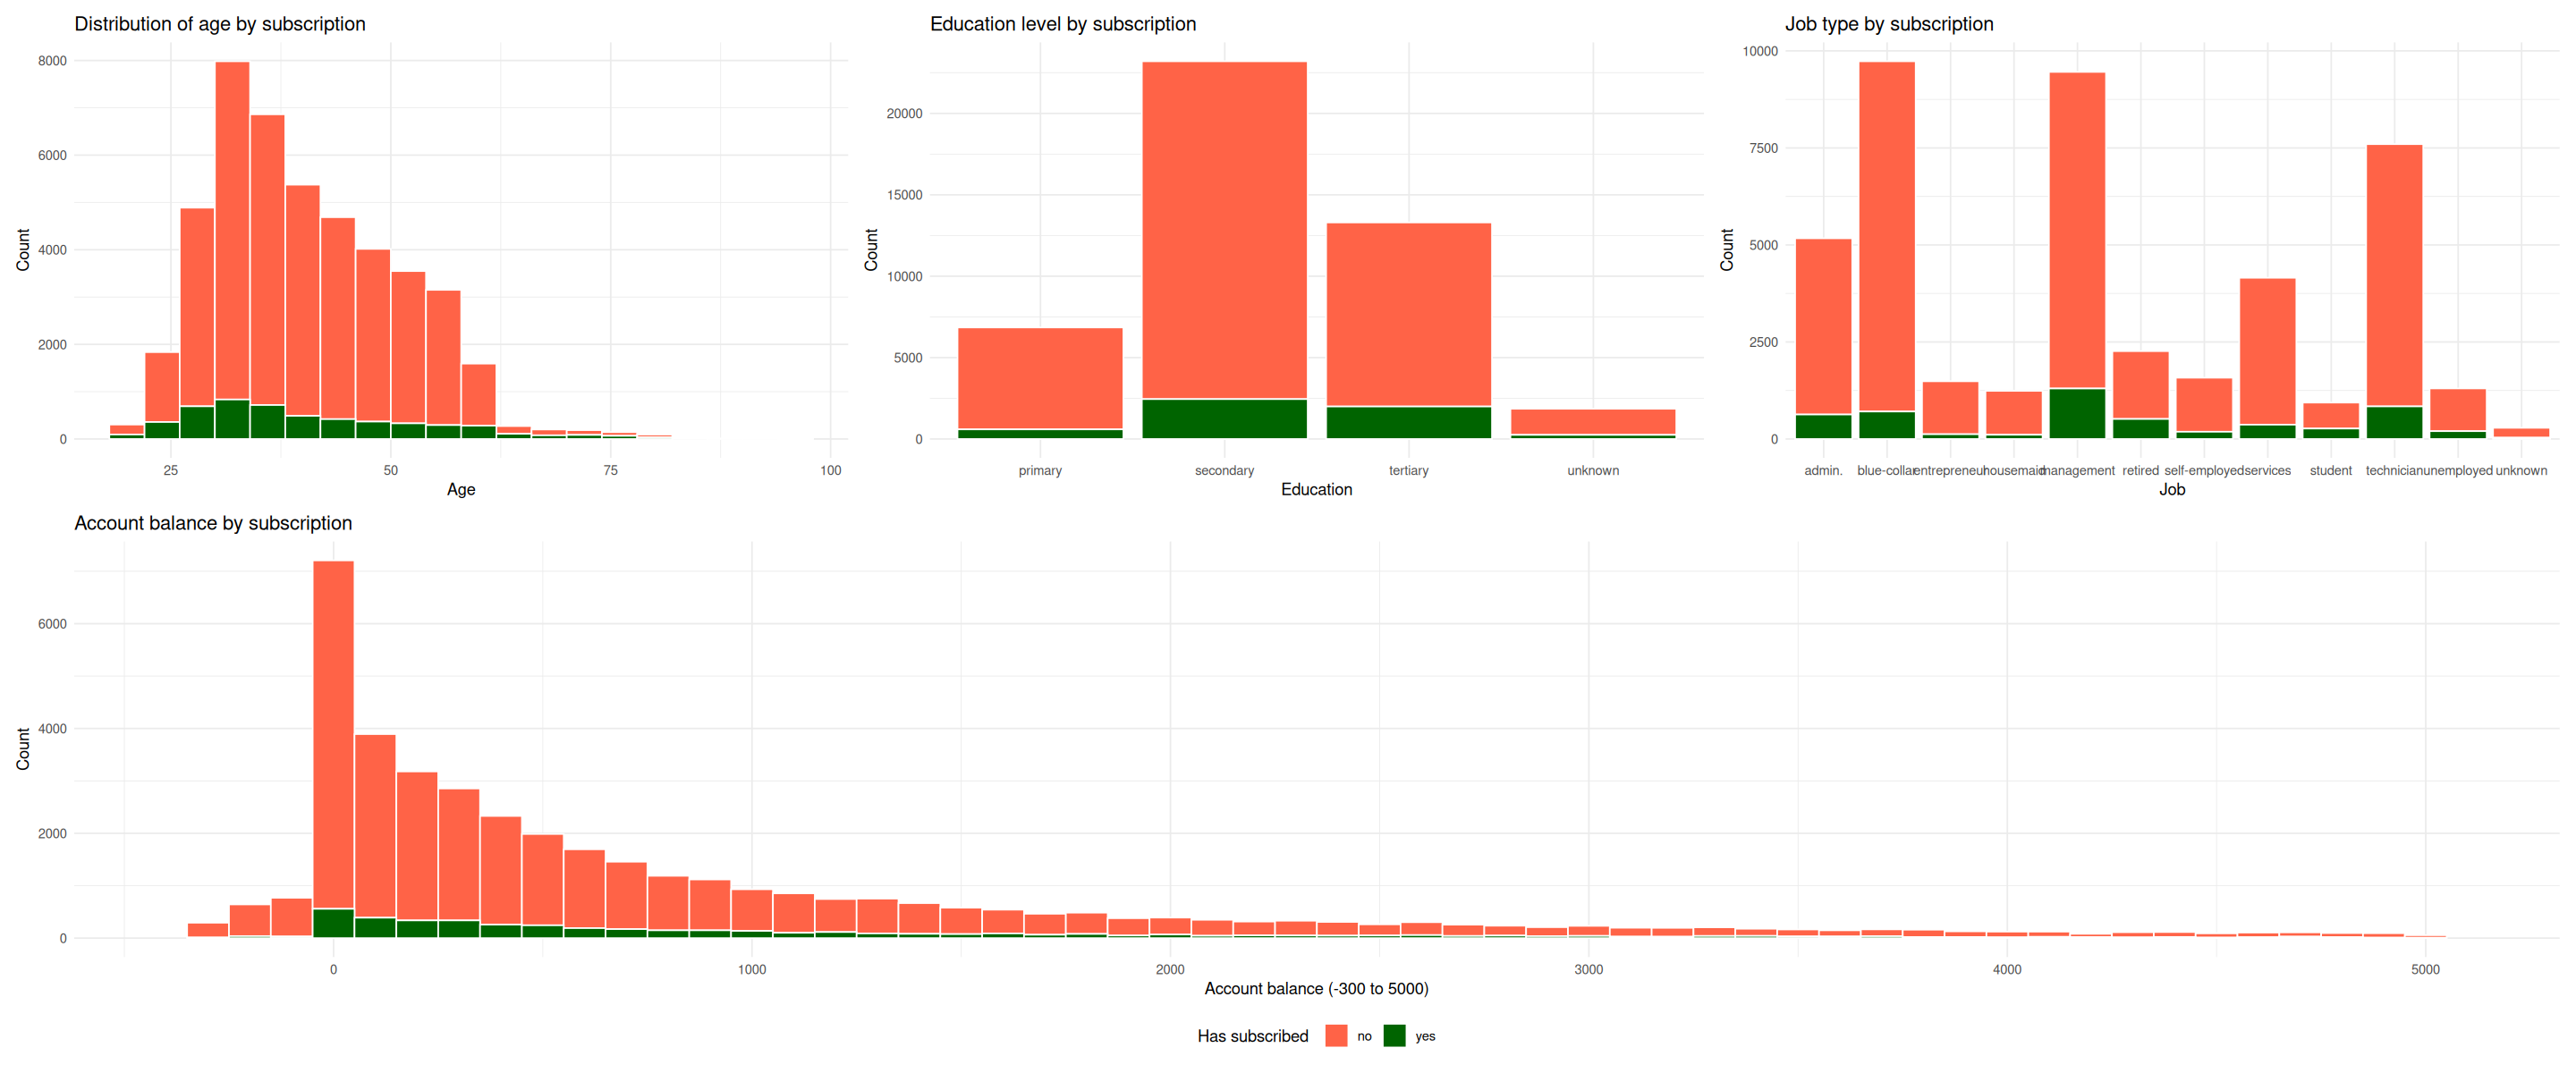

In [79]:

options(repr.plot.width = 8 * 3, repr.plot.height = 5 * 2)
((p1 | p2 | p3) / p4) + plot_layout(guides = "collect") & theme(legend.position = "bottom")